# Phase 3: EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("images", exist_ok = True)

df = pd.read_csv(r"C:\Users\Gafoo\OneDrive\Documents\GitHub\Olist-Customer-Experience-Analytics\notebooks\data\clean_orders.csv",
                 parse_dates=["order_purchase_timestamp", "order_delivered_customer_date"])
print(df.shape)

(95560, 55)


In [3]:
def save(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [4]:
print("orders:",len(df))
print("Avg review score:", df.review_score.mean().round(3))
print("Low-review rate (1-2 stars):", (df.low_review.mean()*100).round(1), "%")
print("Late rate:", (df.is_late.mean()*100).round(1), "%")
print("Repeat customers:", (df.is_repeat_customer.mean()*100).round(1), "%")

orders: 95560
Avg review score: 4.156
Low-review rate (1-2 stars): 12.8 %
Late rate: 6.7 %
Repeat customers: 3.2 %


**Chart 1: How are scores distributed?**

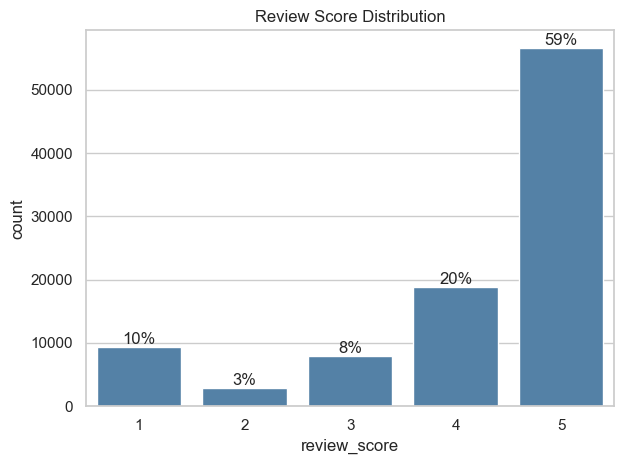

In [5]:
ax = sns.countplot(x = "review_score",data = df, color = "steelblue")
ax.set_title("Review Score Distribution")

for i in ax.containers:
    ax.bar_label(i, labels = [f"{j/len(df):.0%}" for j in i.datavalues])
save("01_score_distribution")


**Chart 2: Late vs on-time, the core question**

In [6]:
df['delay_bucket'] = pd.cut(df.days_late, bins = [-np.inf, 0,3,7, np.inf],
                            labels= ['On Time', '1-3 days late', '4-7 days late', '8+ days late'])


g = df.groupby('delay_bucket', observed= True).agg(
       orders = ('order_id', 'count'),
       avg_score = ('review_score', 'mean'),
       low_rate = ('low_review', 'mean')).reset_index()
print(g)



    delay_bucket  orders  avg_score  low_rate
0        On Time   89182   4.291157  0.092474
1  1-3 days late    1851   3.290654  0.321448
2  4-7 days late    1748   2.102975  0.676773
3   8+ days late    2779   1.696653  0.792731


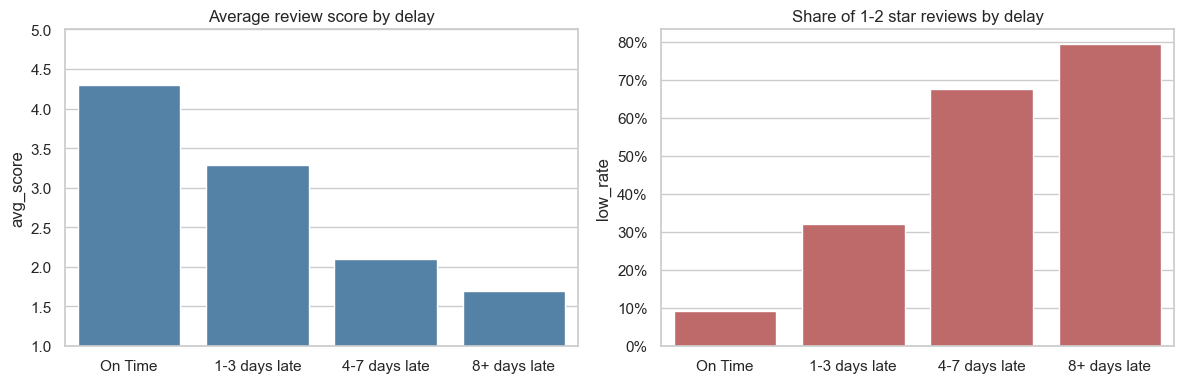

In [7]:
fig, ax = plt.subplots(1,2, figsize = (12,4))
sns.barplot(x='delay_bucket', y = 'avg_score', data = g, color = 'steelblue', ax = ax[0])
ax[0].set_title('Average review score by delay'); ax[0].set_ylim(1,5)
sns.barplot(x = 'delay_bucket', y = 'low_rate', data = g, color = 'indianred', ax=ax[1])
ax[1].set_title("Share of 1-2 star reviews by delay")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for a in ax: a.set_xlabel("")
save("02_delay_vs_score")


**Chart 3: Is delivery the whole story? (the most important chart)**

In [8]:

share_from_late = df.loc[df.low_review == 1, 'is_late'].mean()
print(f"Share of ALL low reviews that come from late orders: {share_from_late:.1%}")
print(f"Share of orders that are late: {df.is_late.mean():.1%}")
print(df.groupby("is_late").low_review.mean())

Share of ALL low reviews that come from late orders: 32.6%
Share of orders that are late: 6.7%
is_late
0    0.092474
1    0.624177
Name: low_review, dtype: float64


**Chart 4: Where is the problem? (states)**

In [10]:
st = (df.groupby("customer_state")
        .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"),
             avg_score=("review_score", "mean"), avg_days=("delivery_days", "mean"))
        .query("orders >= 300").sort_values("late_rate", ascending=False))
st

,orders,late_rate,avg_score,avg_days
customer_state,,,,
AL,393,0.208651,3.847328,24.391858
MA,709,0.172073,3.829337,21.401975
SE,331,0.151057,3.900302,21.299094
PI,470,0.138298,3.993617,19.417021
CE,1267,0.137332,3.940016,21.109708
RJ,12172,0.119619,3.965495,15.156753
BA,3226,0.119033,3.930254,19.186299
PA,929,0.107643,3.912809,23.576964
ES,1966,0.104273,4.078840,15.528993


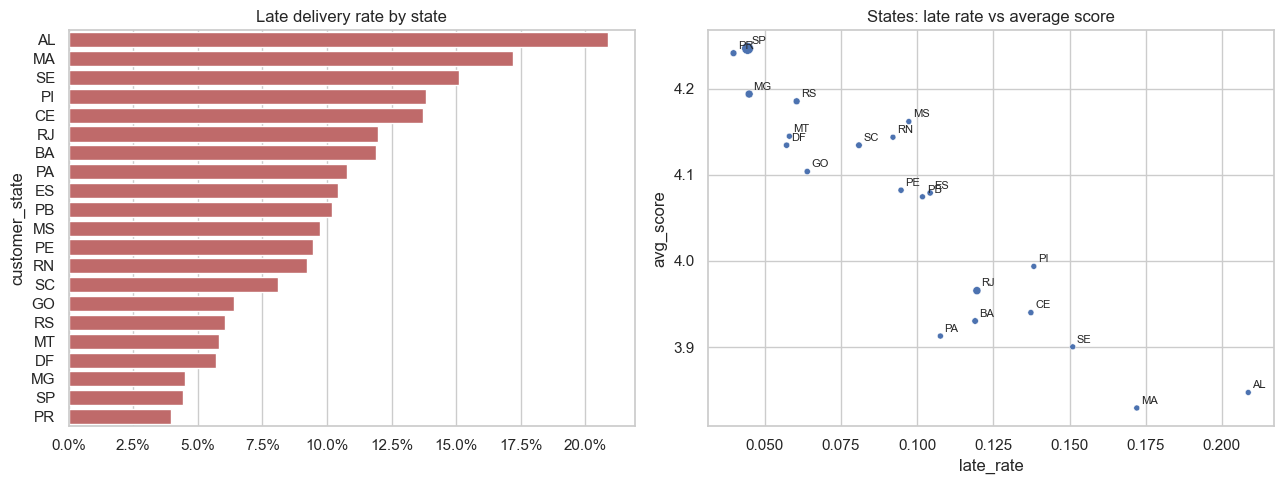

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(y=st.index, x=st.late_rate, color="indianred", ax=ax[0])
ax[0].set_title("Late delivery rate by state"); ax[0].set_xlabel("")
ax[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
sns.scatterplot(x=st.late_rate, y=st.avg_score, size=st.orders, legend=False, ax=ax[1])
for s, r in st.iterrows():
    ax[1].annotate(s, (r.late_rate, r.avg_score), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[1].set_title("States: late rate vs average score")
save("03_states")

**Chart 5: Is it the products? (the seller-relations theory)**

In [13]:
cat = (df.groupby("category")
         .agg(orders=("order_id", "count"), low_rate=("low_review", "mean"),
              late_rate=("is_late", "mean"))
         .query("orders >= 300").sort_values("low_rate", ascending=False).head(12))
cat

,orders,low_rate,late_rate
category,,,
audio,340,0.214706,0.117647
unknown,95047,0.127684,0.066599


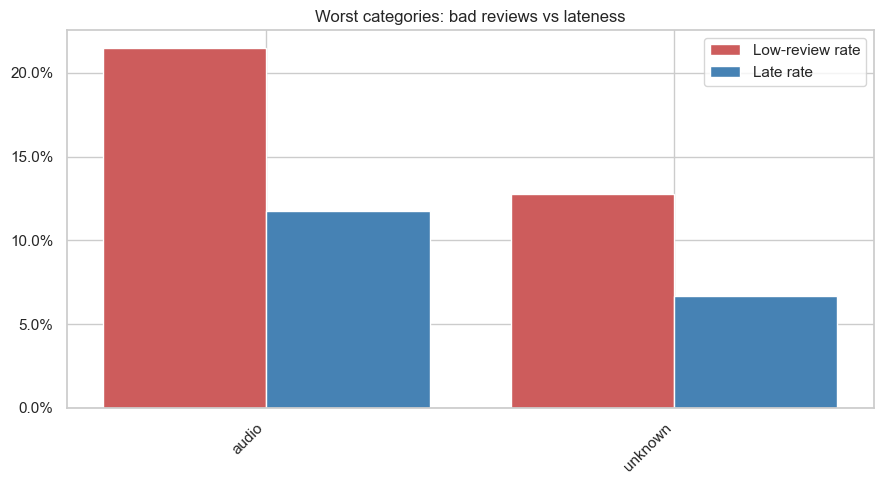

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(cat)); w = 0.4
ax.bar(x - w/2, cat.low_rate, w, label="Low-review rate", color="indianred")
ax.bar(x + w/2, cat.late_rate, w, label="Late rate", color="steelblue")
ax.set_xticks(x); ax.set_xticklabels(cat.index, rotation=45, ha="right")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(); ax.set_title("Worst categories: bad reviews vs lateness")
save("04_categories")

**Chart 6: Are sellers concentrated? (Pareto)**

In [ ]:
s = df.groupby("seller_id").is_late.sum().sort_values(ascending=False)
cum = s.cumsum() / s.sum()
pct_sellers = np.arange(1, len(s) + 1) / len(s)


array([3.41296928e-04, 6.82593857e-04, 1.02389078e-03, ...,
       9.99317406e-01, 9.99658703e-01, 1.00000000e+00], shape=(2930,))

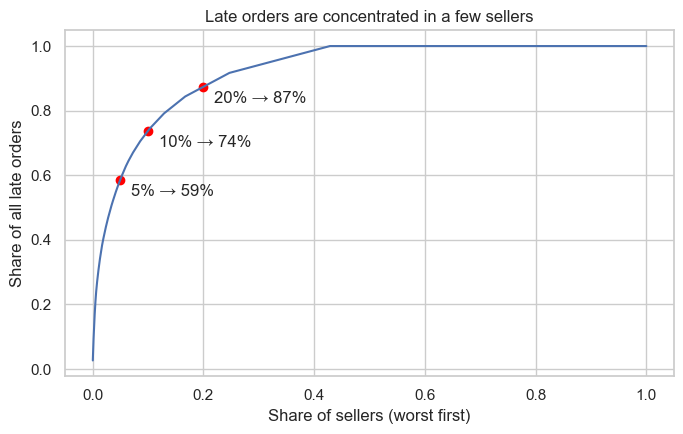

In [18]:
plt.figure(figsize=(7, 4.5))
plt.plot(pct_sellers, cum.values)
plt.xlabel("Share of sellers (worst first)"); plt.ylabel("Share of all late orders")
plt.title("Late orders are concentrated in a few sellers")
for p in [0.05, 0.10, 0.20]:
    v = cum.values[int(p * len(s)) - 1]
    plt.scatter(p, v, color="red"); plt.annotate(f"{p:.0%} → {v:.0%}", (p, v), xytext=(8, -12), textcoords="offset points")
save("05_seller_pareto")

**Chart 7: Distance, freight and handoff**

In [19]:
d = df.dropna(subset=["distance_km"]).copy()
d["dist_bin"] = pd.qcut(d.distance_km, 6, duplicates="drop")
d["freight_bin"] = pd.qcut(d.freight_ratio, 6, duplicates="drop")
d["handoff_bin"] = pd.cut(d.seller_handoff_days, [-np.inf, 1, 3, 5, np.inf],
                          labels=["0-1 day", "2-3 days", "4-5 days", "6+ days"])

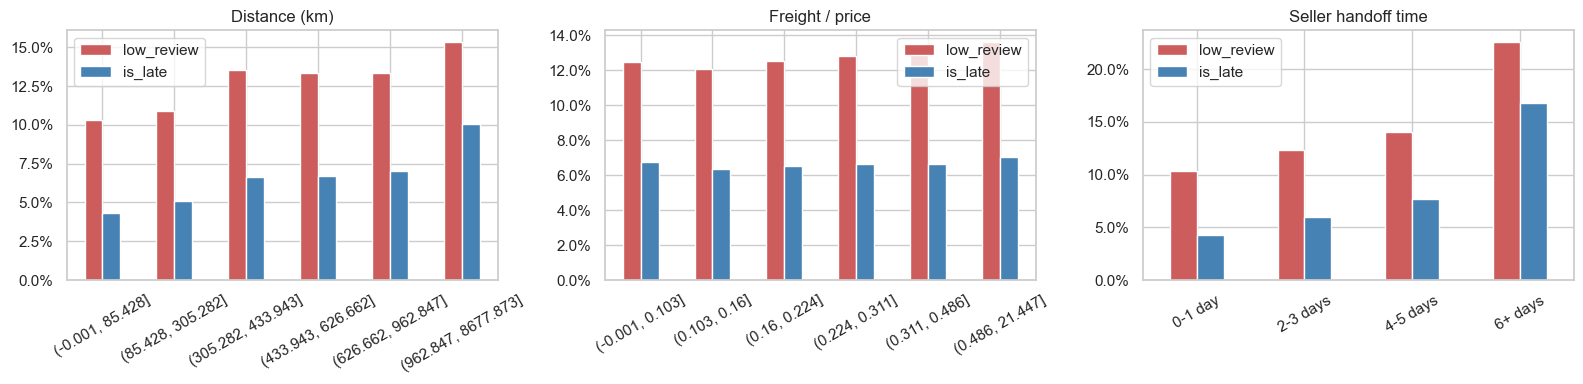

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, title in zip(ax, ["dist_bin", "freight_bin", "handoff_bin"],
                         ["Distance (km)", "Freight / price", "Seller handoff time"]):
    t = d.groupby(col, observed=True)[["low_review", "is_late"]].mean()
    t.plot(kind="bar", ax=a, color=["indianred", "steelblue"])
    a.set_title(title); a.set_xlabel("")
    a.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    a.tick_params(axis="x", rotation=30)
save("06_distance_freight_handoff")

**Chart 8: Monthly trend (are scores really sliding?)**

In [ ]:
m = (df.groupby("purchase_month")
       .agg(orders=("order_id", "count"), avg_score=("review_score", "mean"),
            late_rate=("is_late", "mean")))



,orders,avg_score,late_rate
purchase_month,,,
2017-01,741,4.198381,0.028340
2017-02,1643,4.203287,0.025563
2017-03,2527,4.186783,0.044717
2017-04,2290,4.135371,0.064192
2017-05,3517,4.236281,0.028149
2017-06,3111,4.222758,0.029572
2017-07,3842,4.259500,0.027330
2017-08,4165,4.312845,0.029052
2017-09,4118,4.267848,0.042982


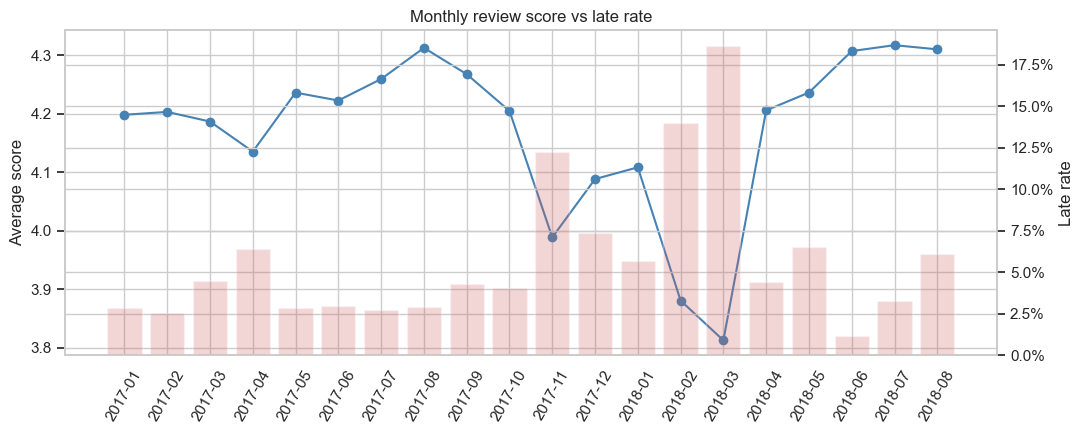

In [23]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(m.index, m.avg_score, marker="o", color="steelblue", label="Avg score")
ax1.set_ylabel("Average score"); ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.bar(m.index, m.late_rate, alpha=0.25, color="indianred")
ax2.set_ylabel("Late rate"); ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax1.set_title("Monthly review score vs late rate")
save("07_monthly_trend")

**Chart 9: Correlation heatmap**

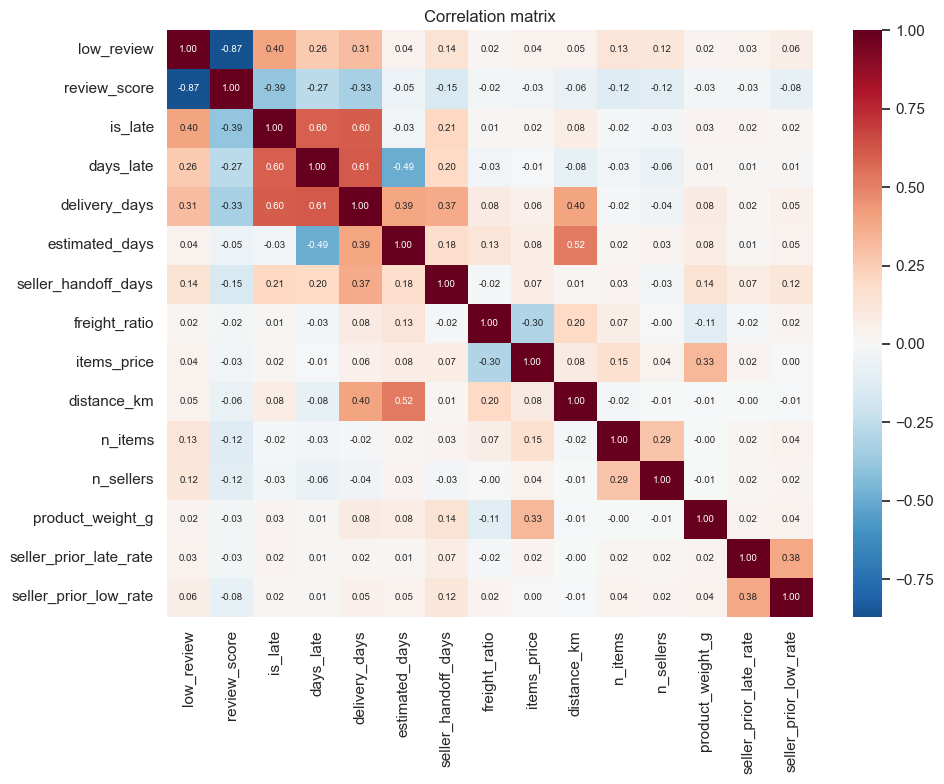

In [24]:
num = ["low_review", "review_score", "is_late", "days_late", "delivery_days", "estimated_days",
       "seller_handoff_days", "freight_ratio", "items_price", "distance_km",
       "n_items", "n_sellers", "product_weight_g", "seller_prior_late_rate", "seller_prior_low_rate"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
save("08_correlation")